# DSCI 552 — Homework 5

Decision trees as interpretable models; LASSO, PCR, and gradient-boosted trees for regression.

**To rerun:** Put the supplied `Homework 5 Data.zip` next to this notebook (or in an `upload/` or `data/` subfolder). The two `.data` files are read directly from the ZIP; manual extraction is unnecessary.

**Name:** ____________________  
**GitHub Username:** ____________________  
**USC ID:** ____________________

**Reproducibility:** Random seed = 42. Training/test split follows the original row order. All model hyperparameters are selected using training-set cross-validation; the held-out test set is evaluated once per fitted model.

## 1. Decision Trees as Interpretable Models

Import packages and define helper functions.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, accuracy_score

SEED = 42
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 15)


def locate_data_archive():
    """Find the course-provided ZIP without assuming a particular OS/path."""
    roots = [Path.cwd(), *list(Path.cwd().parents)[:2]]
    candidates = [root / subdir / "Homework 5 Data.zip"
                  for root in roots for subdir in ("", "upload", "data")]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        "Put 'Homework 5 Data.zip' beside this notebook or in its upload/data folder."
    )


DATA_ZIP = locate_data_archive()


def read_zip_member(filename):
    with ZipFile(DATA_ZIP) as archive:
        return archive.read(filename)


def mse_report(title, model, X_train, y_train, X_test, y_test):
    """Fit on training data and report held-out mean squared error (MSE)."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    print(f"{title}: test MSE = {mse:.6f}; test RMSE = {np.sqrt(mse):.6f}")
    return float(mse)


test_mse = {}
print("Found data archive:", DATA_ZIP.name)

Found data archive: Homework 5 Data.zip


### (a) Obtain Data

Read the 120 samples from `diagnosis.data` (UTF-16, tab-separated; comma decimals). The two diagnosis outcomes are treated as a *joint* four-class target, preserving their multi-label meaning.

In [2]:
acute_cols = [
    "Temperature_C", "Nausea", "Lumbar_pain", "Urine_pushing",
    "Micturition_pains", "Urethra_burning", "Bladder_inflammation", "Nephritis"
]
acute = pd.read_csv(BytesIO(read_zip_member("diagnosis.data")),
                    sep="\t", header=None, names=acute_cols,
                    encoding="utf-16", dtype=str)
acute["Temperature_C"] = acute["Temperature_C"].str.replace(",", ".", regex=False).astype(float)
for col in acute_cols[1:]:
    acute[col] = acute[col].str.strip().str.lower()

X_acute = acute[acute_cols[:6]].copy()
for col in acute_cols[1:6]:
    X_acute[col] = X_acute[col].map({"no": 0, "yes": 1}).astype(int)

y_multi = acute[["Bladder_inflammation", "Nephritis"]].apply(
    lambda col: col.map({"no": 0, "yes": 1})
).astype(int)
y_joint = y_multi.astype(str).agg("".join, axis=1)
class_description = {
    "00": "bladder=no, nephritis=no",
    "01": "bladder=no, nephritis=yes",
    "10": "bladder=yes, nephritis=no",
    "11": "bladder=yes, nephritis=yes",
}

print("Data shape:", acute.shape)
print("Joint diagnosis frequencies:")
print(y_joint.value_counts().sort_index().rename(index=class_description).to_string())
print("Missing data values:", int(acute.isna().sum().sum()))
print(acute.head(5).to_string(index=False))

Data shape: (120, 8)
Joint diagnosis frequencies:
bladder=no, nephritis=no      30
bladder=no, nephritis=yes     31
bladder=yes, nephritis=no     40
bladder=yes, nephritis=yes    19
Missing data values: 0
 Temperature_C Nausea Lumbar_pain Urine_pushing Micturition_pains Urethra_burning Bladder_inflammation Nephritis
          35.5     no         yes            no                no              no                   no        no
          35.9     no          no           yes               yes             yes                  yes        no
          35.9     no         yes            no                no              no                   no        no
          36.0     no          no           yes               yes             yes                  yes        no
          36.0     no         yes            no                no              no                   no        no


### (b) Build a decision tree

Unpruned tree: depth=4, leaves=6, training accuracy=1.000


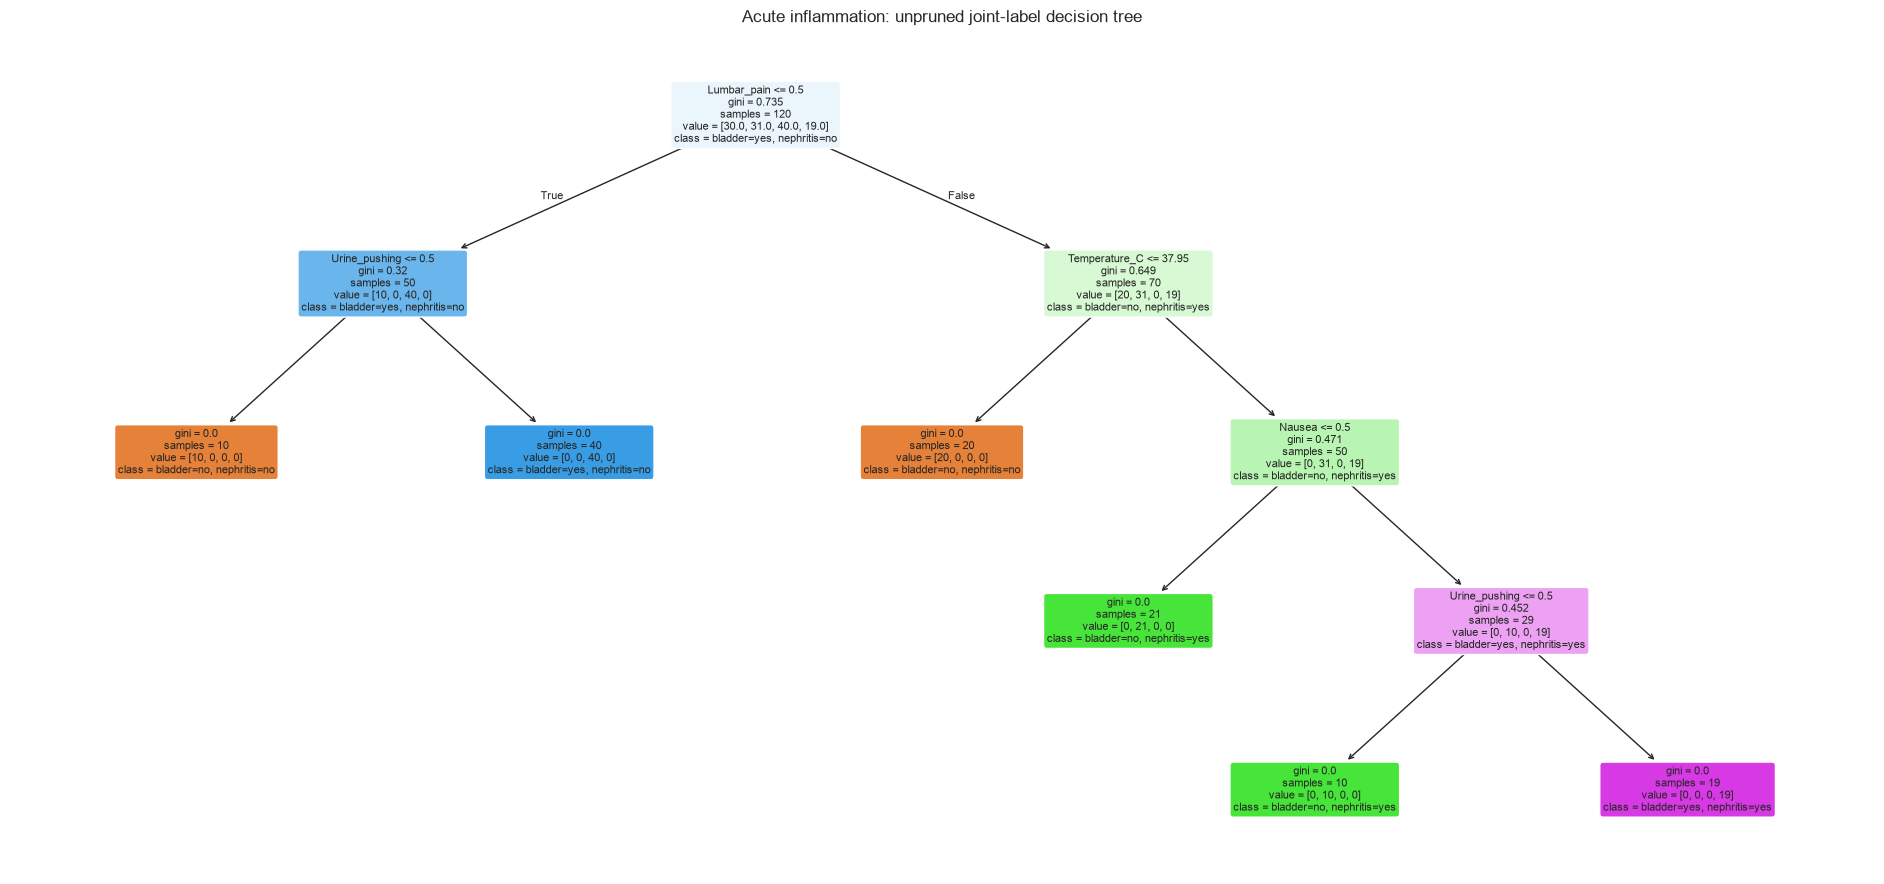

In [3]:
full_tree = DecisionTreeClassifier(random_state=SEED)
full_tree.fit(X_acute, y_joint)
full_accuracy = accuracy_score(y_joint, full_tree.predict(X_acute))
print(f"Unpruned tree: depth={full_tree.get_depth()}, leaves={full_tree.get_n_leaves()}, "
      f"training accuracy={full_accuracy:.3f}")

fig, ax = plt.subplots(figsize=(19, 9))
plot_tree(full_tree, feature_names=X_acute.columns,
          class_names=[class_description[c] for c in full_tree.classes_],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Acute inflammation: unpruned joint-label decision tree")
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [4]:
def readable_conditions(clf, feature_names, descriptions):
    """Extract exact root-to-leaf IF/THEN rules from an sklearn classifier."""
    structure = clf.tree_
    rules = []

    def condition(feature, threshold, go_left):
        op = "<=" if go_left else ">"
        if feature != "Temperature_C" and 0 <= threshold <= 1:
            # All other predictors were encoded no=0, yes=1.
            if go_left:
                return f"{feature} = no" if threshold == 0.5 else f"{feature} {op} {threshold:.3g}"
            return f"{feature} = yes" if threshold == 0.5 else f"{feature} {op} {threshold:.3g}"
        return f"{feature} {op} {threshold:.2f}°C" if feature == "Temperature_C" else f"{feature} {op} {threshold:.3g}"

    def walk(node, path):
        if structure.feature[node] == _tree.TREE_UNDEFINED:
            class_index = np.argmax(structure.value[node][0])
            label = clf.classes_[class_index]
            rules.append((path, descriptions[label], structure.n_node_samples[node]))
            return
        feature = feature_names[structure.feature[node]]
        threshold = structure.threshold[node]
        walk(structure.children_left[node], path + [condition(feature, threshold, True)])
        walk(structure.children_right[node], path + [condition(feature, threshold, False)])

    walk(0, [])
    return rules


def print_rules(clf, title):
    rules = readable_conditions(clf, list(X_acute.columns), class_description)
    print(f"{title} — {len(rules)} IF–THEN rules")
    for index, (conditions, result, count) in enumerate(rules, 1):
        antecedent = " AND ".join(conditions) if conditions else "TRUE"
        print(f"Rule {index}: IF {antecedent} THEN {result} (n={count})")


print_rules(full_tree, "Unpruned tree")

Unpruned tree — 6 IF–THEN rules
Rule 1: IF Lumbar_pain = no AND Urine_pushing = no THEN bladder=no, nephritis=no (n=10)
Rule 2: IF Lumbar_pain = no AND Urine_pushing = yes THEN bladder=yes, nephritis=no (n=40)
Rule 3: IF Lumbar_pain = yes AND Temperature_C <= 37.95°C THEN bladder=no, nephritis=no (n=20)
Rule 4: IF Lumbar_pain = yes AND Temperature_C > 37.95°C AND Nausea = no THEN bladder=no, nephritis=yes (n=21)
Rule 5: IF Lumbar_pain = yes AND Temperature_C > 37.95°C AND Nausea = yes AND Urine_pushing = no THEN bladder=no, nephritis=yes (n=10)
Rule 6: IF Lumbar_pain = yes AND Temperature_C > 37.95°C AND Nausea = yes AND Urine_pushing = yes THEN bladder=yes, nephritis=yes (n=19)


### (d) Cost-complexity pruning for an interpretable decision tree

Generate the candidate penalty values `ccp_alpha` from the full tree. For each value, measure five-fold stratified cross-validation accuracy. Use the **one-standard-error rule**: among candidates whose mean validation accuracy is no more than one SE below the best, pick the largest penalty (simplest tree). Refit to all 120 examples and print its rules. If no smaller candidate clears this accuracy threshold, retain the original tree and state why.

Highest mean five-fold CV accuracy = 0.992 ± 0.008 SE
One-SE threshold = 0.983; chosen ccp_alpha = 0.000000
Pruned tree: depth=4, leaves=6, training accuracy=1.000
No positive pruning alpha retained accuracy within one SE of the best. The full six-leaf tree is already the smallest high-accuracy candidate along the cost-complexity pruning path.


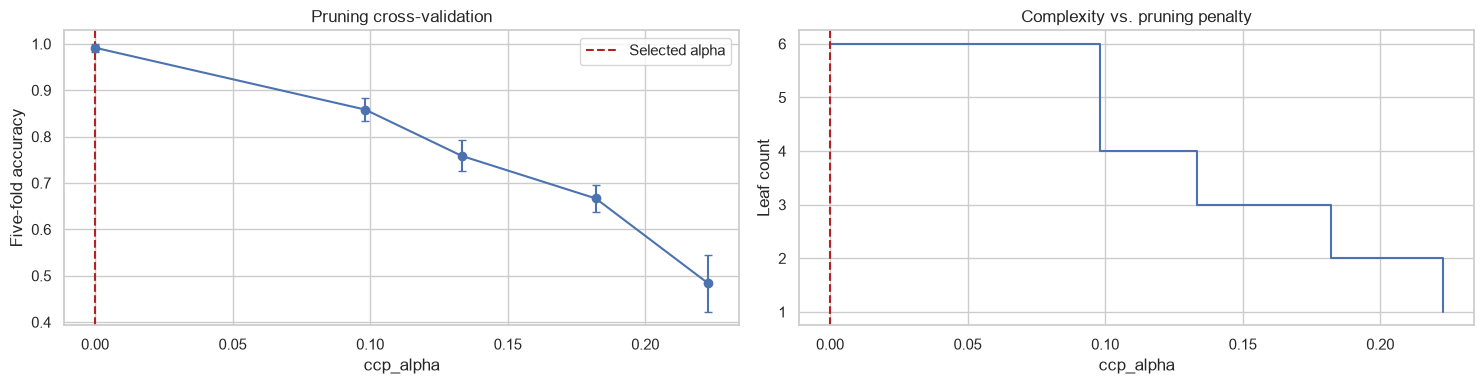

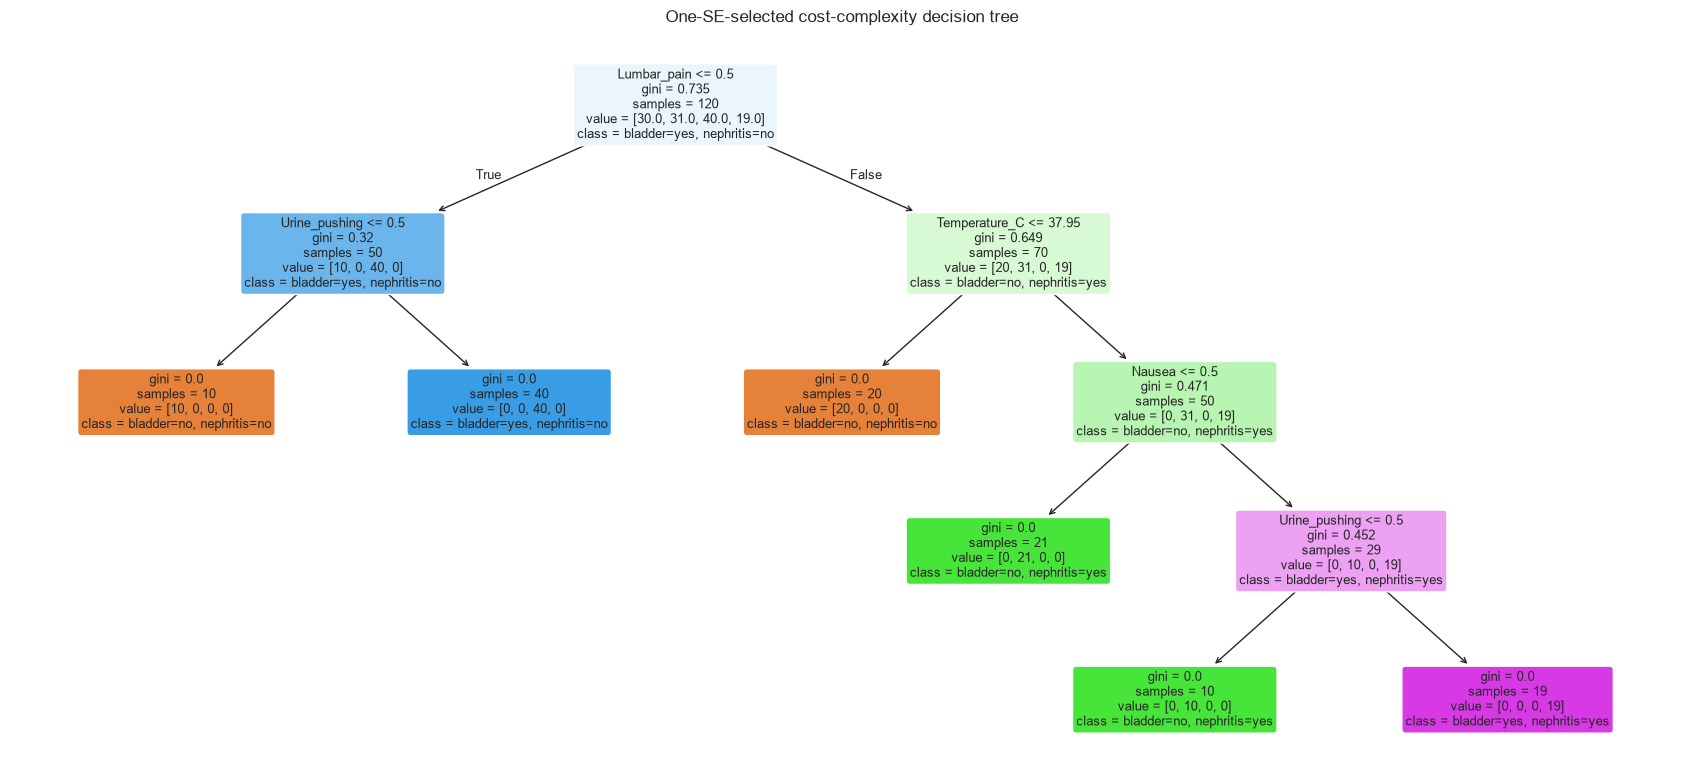

Cost-complexity-selected tree — 6 IF–THEN rules
Rule 1: IF Lumbar_pain = no AND Urine_pushing = no THEN bladder=no, nephritis=no (n=10)
Rule 2: IF Lumbar_pain = no AND Urine_pushing = yes THEN bladder=yes, nephritis=no (n=40)
Rule 3: IF Lumbar_pain = yes AND Temperature_C <= 37.95°C THEN bladder=no, nephritis=no (n=20)
Rule 4: IF Lumbar_pain = yes AND Temperature_C > 37.95°C AND Nausea = no THEN bladder=no, nephritis=yes (n=21)
Rule 5: IF Lumbar_pain = yes AND Temperature_C > 37.95°C AND Nausea = yes AND Urine_pushing = no THEN bladder=no, nephritis=yes (n=10)
Rule 6: IF Lumbar_pain = yes AND Temperature_C > 37.95°C AND Nausea = yes AND Urine_pushing = yes THEN bladder=yes, nephritis=yes (n=19)

Smaller, more aggressively pruned alternative: alpha=0.098167, leaves=4, mean five-fold CV accuracy=0.858


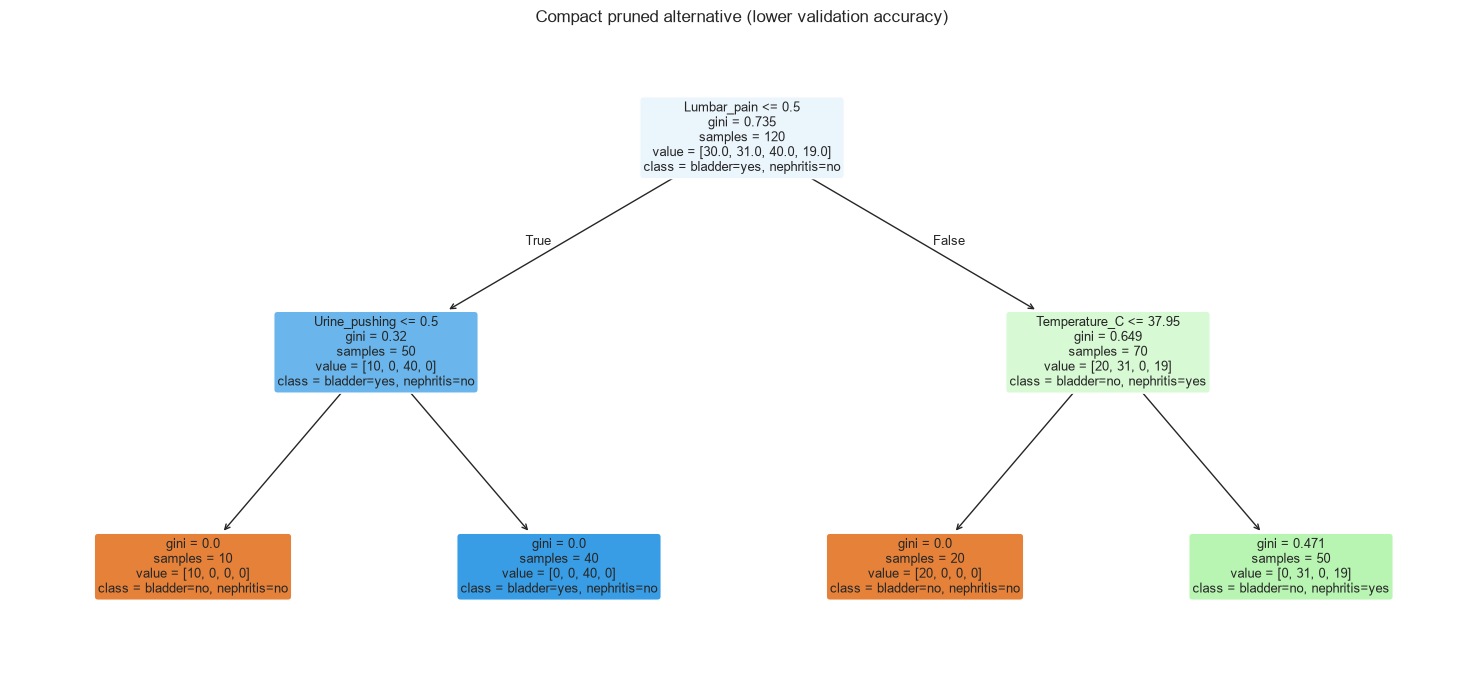

Aggressively pruned alternative — 4 IF–THEN rules
Rule 1: IF Lumbar_pain = no AND Urine_pushing = no THEN bladder=no, nephritis=no (n=10)
Rule 2: IF Lumbar_pain = no AND Urine_pushing = yes THEN bladder=yes, nephritis=no (n=40)
Rule 3: IF Lumbar_pain = yes AND Temperature_C <= 37.95°C THEN bladder=no, nephritis=no (n=20)
Rule 4: IF Lumbar_pain = yes AND Temperature_C > 37.95°C THEN bladder=no, nephritis=yes (n=50)


In [5]:
path = full_tree.cost_complexity_pruning_path(X_acute, y_joint)
alphas = np.unique(path.ccp_alphas)
stratified_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_accuracy = []
for alpha in alphas:
    model = DecisionTreeClassifier(random_state=SEED, ccp_alpha=float(alpha))
    cv_accuracy.append(cross_val_score(model, X_acute, y_joint,
                                       cv=stratified_folds, scoring="accuracy"))
cv_accuracy = np.array(cv_accuracy)
cv_mean = cv_accuracy.mean(axis=1)
cv_se = cv_accuracy.std(axis=1, ddof=1) / np.sqrt(stratified_folds.get_n_splits())
best_idx = int(np.argmax(cv_mean))
threshold = cv_mean[best_idx] - cv_se[best_idx]
chosen_idx = np.flatnonzero(cv_mean >= threshold)[-1]
best_alpha = float(alphas[chosen_idx])

pruned_tree = DecisionTreeClassifier(random_state=SEED, ccp_alpha=best_alpha)
pruned_tree.fit(X_acute, y_joint)
print(f"Highest mean five-fold CV accuracy = {cv_mean[best_idx]:.3f} ± {cv_se[best_idx]:.3f} SE")
print(f"One-SE threshold = {threshold:.3f}; chosen ccp_alpha = {best_alpha:.6f}")
print(f"Pruned tree: depth={pruned_tree.get_depth()}, "
      f"leaves={pruned_tree.get_n_leaves()}, "
      f"training accuracy={pruned_tree.score(X_acute, y_joint):.3f}")
if best_alpha == 0:
    print("No positive pruning alpha retained accuracy within one SE of the best. "
          "The full six-leaf tree is already the smallest high-accuracy "
          "candidate along the cost-complexity pruning path.")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].errorbar(alphas, cv_mean, yerr=cv_se, marker="o", capsize=3)
axes[0].axvline(best_alpha, color="firebrick", ls="--", label="Selected alpha")
axes[0].set(xlabel="ccp_alpha", ylabel="Five-fold accuracy", title="Pruning cross-validation")
axes[0].legend()
tree_sizes = [DecisionTreeClassifier(random_state=SEED, ccp_alpha=float(a))
              .fit(X_acute, y_joint).get_n_leaves() for a in alphas]
axes[1].step(alphas, tree_sizes, where="post")
axes[1].axvline(best_alpha, color="firebrick", ls="--")
axes[1].set(xlabel="ccp_alpha", ylabel="Leaf count", title="Complexity vs. pruning penalty")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(17, 8))
plot_tree(pruned_tree, feature_names=X_acute.columns,
          class_names=[class_description[c] for c in pruned_tree.classes_],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("One-SE-selected cost-complexity decision tree")
plt.tight_layout()
plt.show()

print_rules(pruned_tree, "Cost-complexity-selected tree")

# Also show the first genuinely smaller tree to make the accuracy-versus-
# interpretability tradeoff explicit, even though the one-SE rule rejects it.
positive_alphas = alphas[alphas > 0]
if len(positive_alphas):
    compact_alpha = float(positive_alphas[0])
    compact_tree = DecisionTreeClassifier(random_state=SEED, ccp_alpha=compact_alpha)
    compact_tree.fit(X_acute, y_joint)
    compact_idx = int(np.where(alphas == compact_alpha)[0][0])
    print(f"\nSmaller, more aggressively pruned alternative: "
          f"alpha={compact_alpha:.6f}, leaves={compact_tree.get_n_leaves()}, "
          f"mean five-fold CV accuracy={cv_mean[compact_idx]:.3f}")
    fig, ax = plt.subplots(figsize=(15, 7))
    plot_tree(compact_tree, feature_names=X_acute.columns,
              class_names=[class_description[c] for c in compact_tree.classes_],
              filled=True, rounded=True, fontsize=9, ax=ax)
    ax.set_title("Compact pruned alternative (lower validation accuracy)")
    plt.tight_layout()
    plt.show()
    print_rules(compact_tree, "Aggressively pruned alternative")

**Interpretation:** Both original diseases are predicted together using their four possible label combinations. Pruning offers simpler rules only when validation accuracy remains sufficiently high. In this data, the next smaller cost-complexity candidate reduces the number of leaves from six to four, but its mean cross-validation accuracy falls from approximately 99.2% to 85.8%. Thus, the one-SE rule retains the original six-leaf tree: its six readable rules are preferable to a shorter but substantially less reliable set. Training accuracy is descriptive only; selection uses cross-validation.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
names_text = read_zip_member("communities.names").decode("latin-1")
column_names = re.findall(r"(?m)^@attribute\s+(\S+)\s+", names_text)
crime = pd.read_csv(BytesIO(read_zip_member("communities.data")),
                    header=None, names=column_names, na_values="?")

# The documentation flags these 5 identifier/fold fields as non-predictive.
id_columns = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
feature_names = [c for c in crime.columns if c not in id_columns + [target]]
X_raw = crime[feature_names].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(crime[target], errors="coerce")

assert crime.shape == (1994, 128), crime.shape
assert y.notna().all(), "Target should have no missing values."
assert len(feature_names) == 122
X_train_raw, X_test_raw = X_raw.iloc[:1495].copy(), X_raw.iloc[1495:].copy()
y_train, y_test = y.iloc[:1495].copy(), y.iloc[1495:].copy()
assert len(X_train_raw) == 1495 and len(X_test_raw) == 499

print(f"Shape: {crime.shape} | predictors: {len(feature_names)}")
print(f"Train: {X_train_raw.shape}; test: {X_test_raw.shape}")
print("Ignored non-predictive attributes:", id_columns)
print("Target:", target)

Shape: (1994, 128) | predictors: 122
Train: (1495, 122); test: (499, 122)
Ignored non-predictive attributes: ['state', 'county', 'community', 'communityname', 'fold']
Target: ViolentCrimesPerPop


### (b) Missing values

In [7]:
# Decide which columns to use ONLY from the training portion.
# An entirely missing / invariant training column cannot be estimated usefully.
all_missing = X_train_raw.columns[X_train_raw.isna().all()].tolist()
invariant = X_train_raw.columns[X_train_raw.nunique(dropna=True) <= 1].tolist()
dropped = sorted(set(all_missing + invariant))
retained = [col for col in feature_names if col not in dropped]
X_train = X_train_raw[retained]
X_test = X_test_raw[retained]

# Exploratory plots use medians learned from the training data only.
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), index=X_train.index, columns=retained)
X_test_imp = pd.DataFrame(imputer.transform(X_test), index=X_test.index, columns=retained)
X_all_imp = pd.concat([X_train_imp, X_test_imp], axis=0)

print("Missing predictor values (all rows):", int(X_raw.isna().sum().sum()))
print("Predictors with missing entries:", int((X_raw.isna().sum() > 0).sum()))
print("Dropped entirely missing or invariant training predictors:", dropped)
print("Predictors retained:", len(retained))
print("Missing values after train-fitted median imputation:", int(X_all_imp.isna().sum().sum()))

# Every cross-validation model below uses a new imputer INSIDE its pipeline,
# so its validation fold never influences the median fitted by that fold.

Missing predictor values (all rows): 36851
Predictors with missing entries: 23
Dropped entirely missing or invariant training predictors: []
Predictors retained: 122
Missing values after train-fitted median imputation: 0


### (c) Plot a correlation matrix

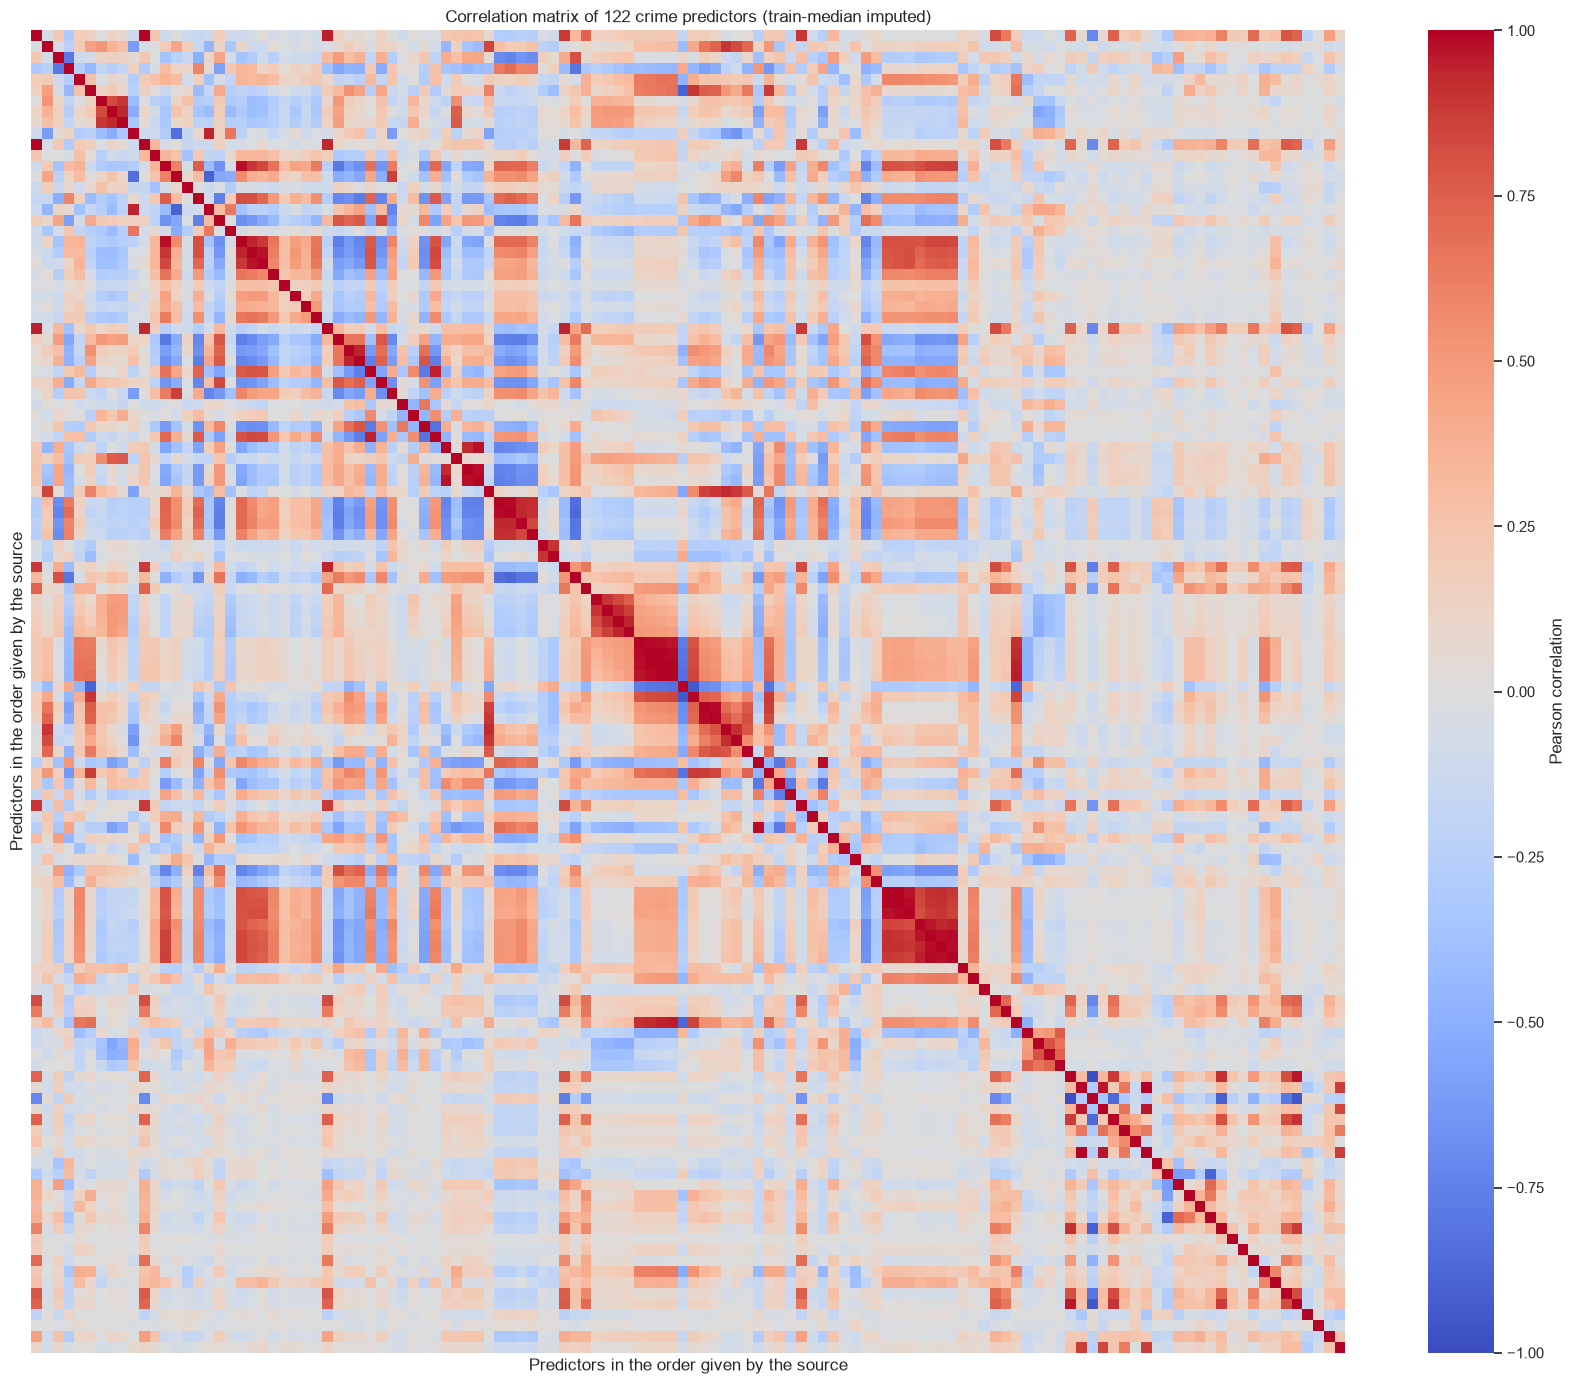

Ten strongest absolute inter-feature correlations:
LemasSwFTPerPop  PolicPerPop          0.999994
PctRecImmig8     PctRecImmig10        0.995525
OwnOccLowQuart   OwnOccMedVal         0.994481
PctRecImmig5     PctRecImmig8         0.993433
population       numbUrban            0.993112
LemasSwornFT     LemasSwFTFieldOps    0.991590
OwnOccMedVal     OwnOccHiQuart        0.991302
PctRecentImmig   PctRecImmig5         0.988999
RentMedian       MedRent              0.988585
PctRecImmig5     PctRecImmig10        0.985616


In [8]:
correlation_matrix = X_all_imp.corr()
fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0,
            vmin=-1, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title(f"Correlation matrix of {len(retained)} crime predictors (train-median imputed)")
ax.set_xlabel("Predictors in the order given by the source")
ax.set_ylabel("Predictors in the order given by the source")
plt.tight_layout()
plt.show()

pairs = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
strongest = pairs.stack().abs().sort_values(ascending=False).head(10)
print("Ten strongest absolute inter-feature correlations:")
print(strongest.to_string())

### (d) Calculate the Coefficient of Variation CV

In [9]:
# CV = sample standard deviation / |sample mean|.  At zero mean CV is undefined.
sample_mean = X_all_imp.mean()
sample_std = X_all_imp.std(ddof=1)
coefficient_variation = sample_std.div(sample_mean.abs().replace(0, np.nan))
cv_table = pd.DataFrame({"mean": sample_mean, "std_sample": sample_std,
                         "CV": coefficient_variation}).sort_values("CV", ascending=False)
print(f"CV calculated for {len(cv_table)} retained features; "
      f"undefined at zero mean: {cv_table.CV.isna().sum()}")
print("Top 20 by CV:")
print(cv_table.head(20).round(5).to_string())

CV calculated for 122 retained features; undefined at zero mean: 0
Top 20 by CV:
                        mean  std_sample       CV
PctPolicAsian        0.01838     0.10010  5.44783
NumStreet            0.02278     0.10040  4.40770
NumInShelters        0.02944     0.10261  3.48548
NumIlleg             0.03629     0.10867  2.99420
NumImmig             0.03006     0.08719  2.90050
LemasPctOfficDrugUn  0.09405     0.24033  2.55527
NumUnderPov          0.05551     0.12794  2.30497
population           0.05759     0.12691  2.20350
LemasSwornFT         0.02794     0.05814  2.08071
numbUrban            0.06407     0.12826  2.00174
HousVacant           0.07682     0.15046  1.95878
LandArea             0.06523     0.10946  1.67803
racePctHisp          0.14402     0.23249  1.61428
PolicOperBudg        0.03747     0.05857  1.56290
PctNotSpeakEnglWell  0.15059     0.21972  1.45907
PctUsePubTrans       0.16169     0.22905  1.41667
racepctblack         0.17963     0.25344  1.41092
LemasTotalReq      

### (e) Scatter plots and box plots for highest CV features

floor(sqrt(128)) = 11 highest-CV predictors:
 1. PctPolicAsian
 2. NumStreet
 3. NumInShelters
 4. NumIlleg
 5. NumImmig
 6. LemasPctOfficDrugUn
 7. NumUnderPov
 8. population
 9. LemasSwornFT
10. numbUrban
11. HousVacant


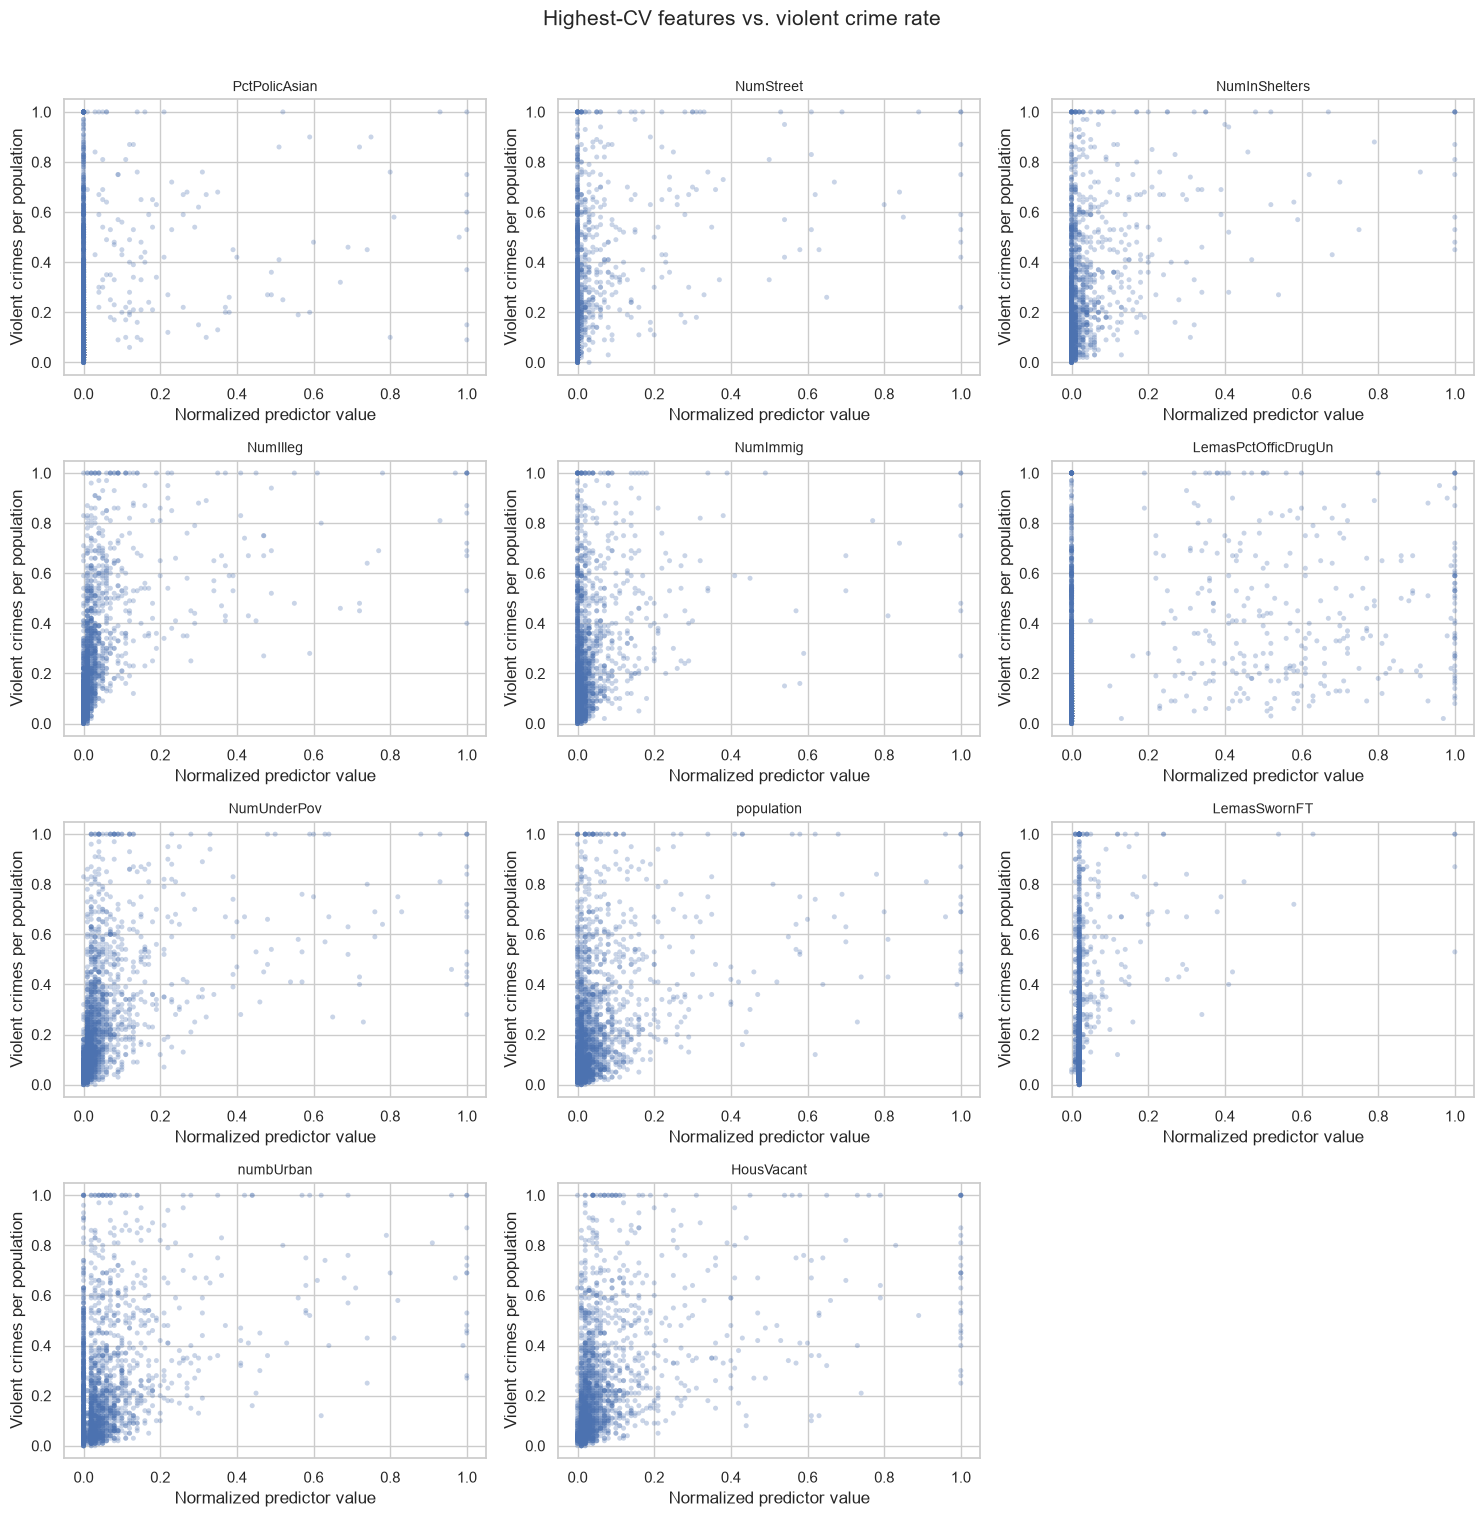

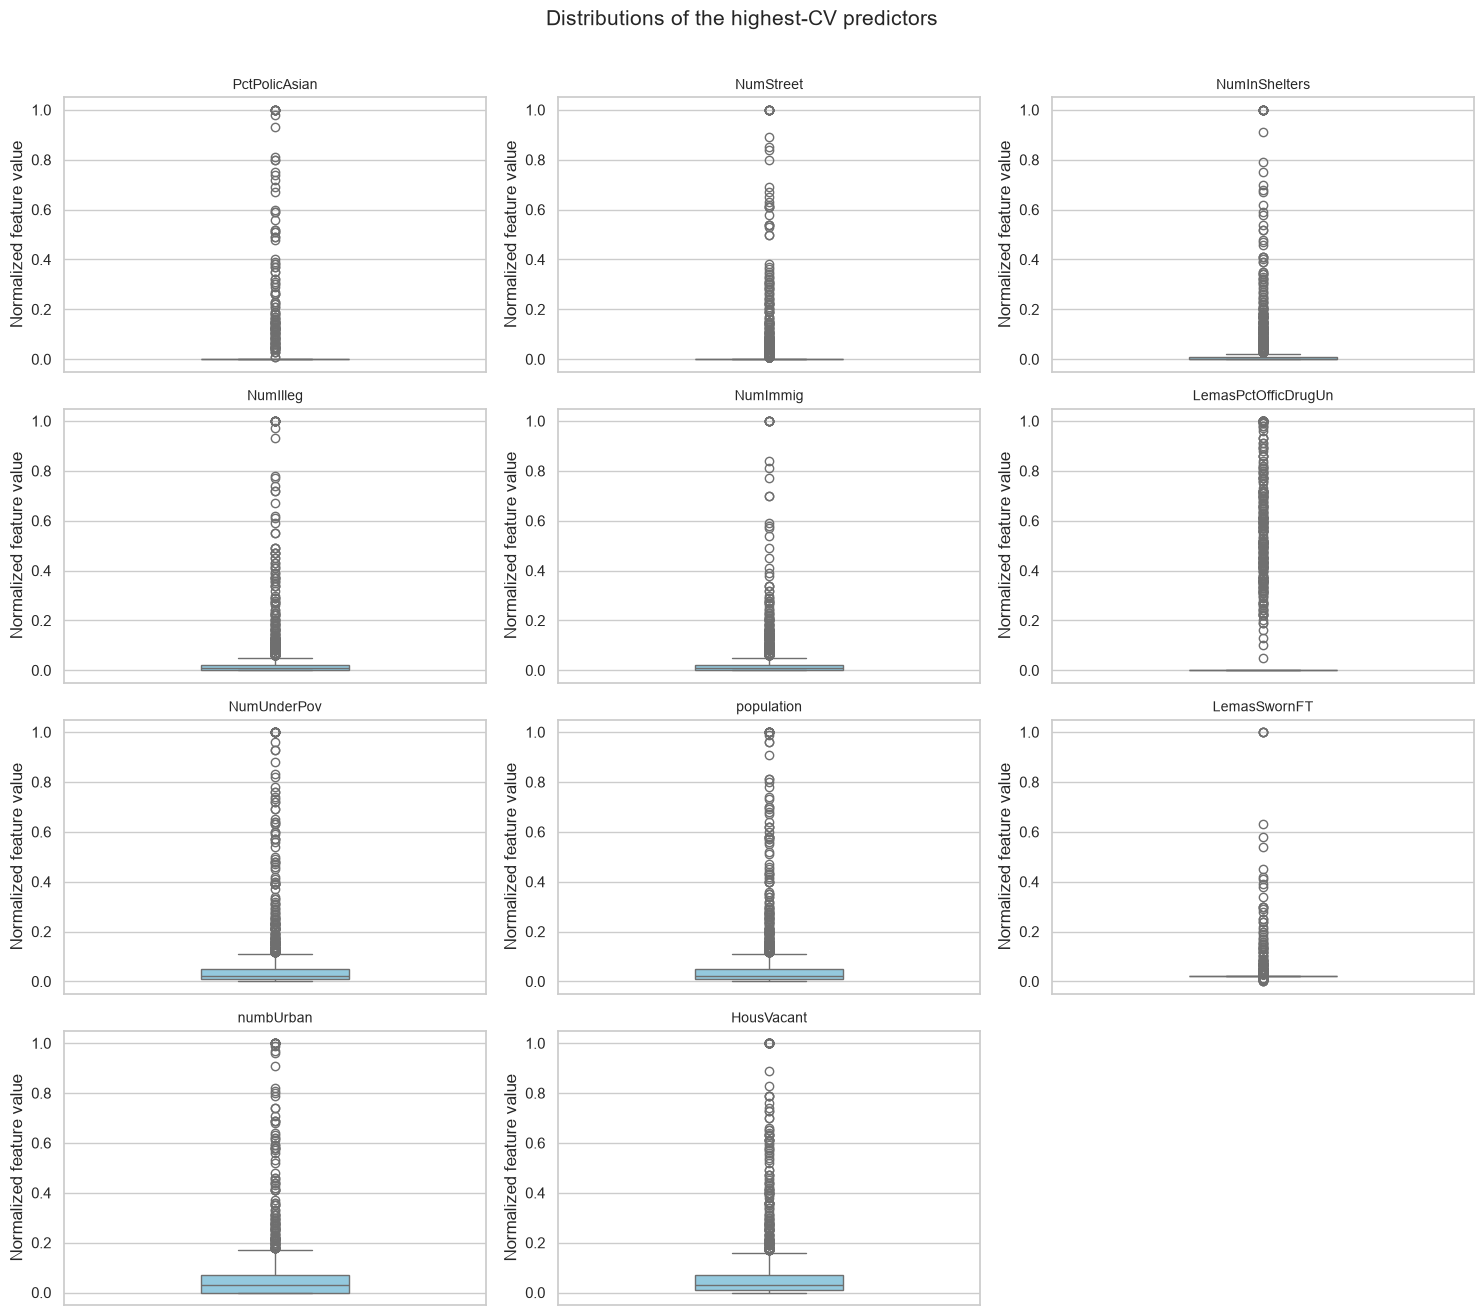

Interpretation: High CV describes relative dispersion, NOT predictive relevance. Scatterplots can suggest trends and outliers, but cannot establish a feature's statistical significance after adjustment for other predictors. Formal inference or out-of-sample model analysis would be needed.


In [10]:
k_top = math.floor(math.sqrt(crime.shape[1]))  # floor(sqrt(128)) = 11
top_features = cv_table["CV"].dropna().head(k_top).index.tolist()
print(f"floor(sqrt({crime.shape[1]})) = {k_top} highest-CV predictors:")
print("\n".join(f"{i:2d}. {feature}" for i, feature in enumerate(top_features, start=1)))

fig, axes = plt.subplots(math.ceil(k_top / 3), 3, figsize=(15, 15))
for ax, col in zip(axes.flat, top_features):
    ax.scatter(X_all_imp[col], y, alpha=0.30, s=13, edgecolors="none")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Normalized predictor value")
    ax.set_ylabel("Violent crimes per population")
for ax in axes.flat[k_top:]:
    ax.axis("off")
fig.suptitle("Highest-CV features vs. violent crime rate", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(math.ceil(k_top / 3), 3, figsize=(15, 13))
for ax, col in zip(axes.flat, top_features):
    sns.boxplot(y=X_all_imp[col], ax=ax, color="skyblue", width=.35)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("Normalized feature value")
for ax in axes.flat[k_top:]:
    ax.axis("off")
fig.suptitle("Distributions of the highest-CV predictors", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

print("Interpretation: High CV describes relative dispersion, NOT predictive relevance. "
      "Scatterplots can suggest trends and outliers, but cannot establish a "
      "feature's statistical significance after adjustment for other predictors. "
      "Formal inference or out-of-sample model analysis would be needed.")

**Answer to (e):** No. High coefficient of variation measures how variable a feature is *relative to its mean*; it does not measure its effect on crime. Scatter plots can reveal obvious associations, nonlinear patterns, or outliers, but they cannot establish statistical significance because correlations among predictors, confounders, and sampling uncertainty are not accounted for.

### (f) Fit a linear model

In [11]:
ordinary_least_squares = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])
test_mse["OLS"] = mse_report("Ordinary least squares", ordinary_least_squares,
                             X_train, y_train, X_test, y_test)
baseline_mse = mean_squared_error(y_test, np.repeat(y_train.mean(), len(y_test)))
print(f"Train-mean baseline test MSE = {baseline_mse:.6f}")

Ordinary least squares: test MSE = 0.017966; test RMSE = 0.134038
Train-mean baseline test MSE = 0.047666


### (g) Fit a ridge regression model

In [12]:
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])
ridge_grid = GridSearchCV(ridge_pipeline, {"ridge__alpha": np.logspace(-4, 4, 60)},
                          scoring="neg_mean_squared_error", cv=CV, n_jobs=1)
test_mse["Ridge"] = mse_report("Ridge regression", ridge_grid,
                               X_train, y_train, X_test, y_test)
print(f"Chosen ridge lambda = {ridge_grid.best_params_['ridge__alpha']:.7g}")
print(f"Five-fold CV MSE = {-ridge_grid.best_score_:.6f}")

Ridge regression: test MSE = 0.017372; test RMSE = 0.131803
Chosen ridge lambda = 126.3848
Five-fold CV MSE = 0.019738


### (h) Fit a LASSO model

In [13]:
lasso_alphas = np.logspace(-5, -0.5, 28)
lasso_models = {}
for standardized in (False, True):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if standardized:
        steps.append(("scaler", StandardScaler()))
    steps.append(("lasso", Lasso(max_iter=50000, random_state=SEED)))
    grid = GridSearchCV(Pipeline(steps), {"lasso__alpha": lasso_alphas},
                        scoring="neg_mean_squared_error", cv=CV, n_jobs=1)
    label = "LASSO (standardized)" if standardized else "LASSO (original scale)"
    test_mse[label] = mse_report(label, grid, X_train, y_train, X_test, y_test)
    lasso_models[label] = grid
    selected = pd.Series(grid.best_estimator_.named_steps["lasso"].coef_, index=retained)
    selected = selected[selected.abs() > 1e-8].sort_values(key=np.abs, ascending=False)
    print(f"  Chosen lambda: {grid.best_params_['lasso__alpha']:.7g}; CV MSE: {-grid.best_score_:.6f}")
    print(f"  Selected variables ({len(selected)}):")
    print("  " + ", ".join(selected.index) if len(selected) else "  None")
    print()

raw_lasso_mse = test_mse["LASSO (original scale)"]
scaled_lasso_mse = test_mse["LASSO (standardized)"]
print("Comparison: Standardization " +
      ("improved" if scaled_lasso_mse < raw_lasso_mse else "did not improve") +
      f" held-out MSE by {abs(scaled_lasso_mse-raw_lasso_mse):.6f}. "
      "Although the original attributes lie in [0,1], their variances differ "
      "and scaling changes the relative L1 penalty across coefficients.")

LASSO (original scale): test MSE = 0.017659; test RMSE = 0.132886
  Chosen lambda: 0.0001; CV MSE: 0.019525
  Selected variables (75):
  agePct12t29, racepctblack, PctPersDenseHous, PctKids2Par, MedRent, RentLowQ, NumStreet, PctEmploy, MalePctNevMarr, PctPopUnderPov, PctWorkMom, MalePctDivorce, HousVacant, pctWInvInc, pctWRetire, NumImmig, NumIlleg, FemalePctDiv, PctIlleg, PolicReqPerOffic, pctWWage, MedRentPctHousInc, PctLargHouseOccup, PctNotSpeakEnglWell, MedOwnCostPctIncNoMtg, LemasSwFTFieldPerPop, agePct12t21, PctVacantBoarded, PersPerOccupHous, NumInShelters, PctHousLess3BR, PctPersOwnOccup, whitePerCap, PctVacMore6Mos, PctHousOccup, pctWSocSec, PctForeignBorn, PctUsePubTrans, pctWPubAsst, pctUrban, PctRecImmig10, LemasGangUnitDeploy, PctYoungKids2Par, LandArea, NumKindsDrugsSeiz, indianPerCap, PolicCars, pctWFarmSelf, AsianPerCap, PctHousNoPhone, PctWOFullPlumb, RacialMatchCommPol, HispPerCap, PctSameCity85, OtherPerCap, PctPolicAsian, PctPolicHisp, blackPerCap, PctLess9thGrade,

**Answer to (h):** Compare test-set MSE for the raw and standardized LASSO fits in the output. Standardizing is still worth testing even though the data were originally normalized to 0–1: L1 penalization is affected by each feature's spread, not just its numeric range. Selected variables are those with nonzero fitted coefficients.

### (i) Fit a PCR model

Principal components regression: test MSE = 0.018350; test RMSE = 0.135460
Chosen number of principal components M = 60 / 122
Five-fold CV MSE at M = 60: 0.020210
Variance explained by chosen components: 98.06%


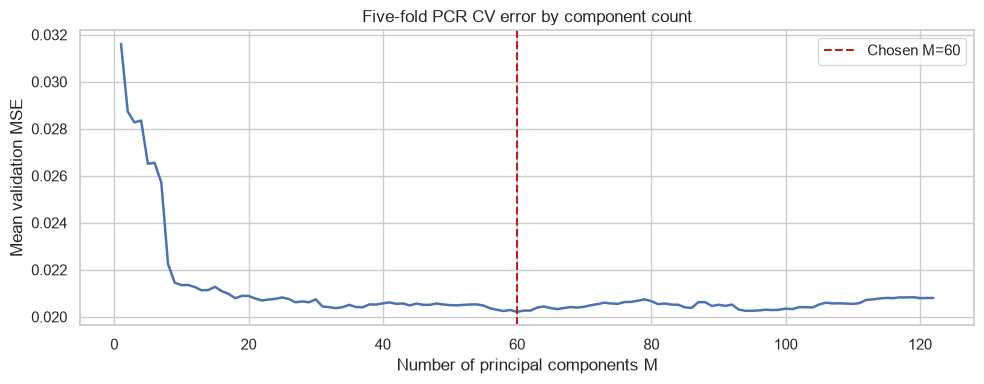

In [14]:
# Evaluate EVERY available component count with five-fold CV.
# For a fixed PCA fit, its orthogonal component regressions can be accumulated
# using one SVD per fold instead of refitting a separate PCA for every M.
pcr_fold_errors = []
n_components = len(retained)
for fit_idx, valid_idx in CV.split(X_train):
    x_fit, x_valid = X_train.iloc[fit_idx], X_train.iloc[valid_idx]
    y_fit = y_train.iloc[fit_idx].to_numpy()
    y_valid = y_train.iloc[valid_idx].to_numpy()
    fill = SimpleImputer(strategy="median")
    x_fit_filled = fill.fit_transform(x_fit)
    x_valid_filled = fill.transform(x_valid)
    scale = StandardScaler()
    x_fit_scaled = scale.fit_transform(x_fit_filled)
    x_valid_scaled = scale.transform(x_valid_filled)
    pca_fold = PCA(n_components=n_components, svd_solver="full")
    fit_scores = pca_fold.fit_transform(x_fit_scaled)
    valid_scores = pca_fold.transform(x_valid_scaled)

    centered_y = y_fit - y_fit.mean()
    denom = np.sum(fit_scores**2, axis=0)
    coef = np.divide(fit_scores.T @ centered_y, denom,
                     out=np.zeros_like(denom), where=denom > 1e-12)
    progressive_predictions = y_fit.mean() + np.cumsum(valid_scores * coef, axis=1)
    pcr_fold_errors.append(np.mean((progressive_predictions - y_valid[:, None])**2, axis=0))

pcr_cv_mse = np.mean(pcr_fold_errors, axis=0)
best_m = int(np.argmin(pcr_cv_mse)) + 1
pcr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=best_m, svd_solver="full")),
    ("regressor", LinearRegression())
])
test_mse["PCR"] = mse_report("Principal components regression", pcr,
                             X_train, y_train, X_test, y_test)
print(f"Chosen number of principal components M = {best_m} / {n_components}")
print(f"Five-fold CV MSE at M = {best_m}: {pcr_cv_mse[best_m-1]:.6f}")
print(f"Variance explained by chosen components: "
      f"{pcr.named_steps['pca'].explained_variance_ratio_.sum():.2%}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1, n_components+1), pcr_cv_mse, linewidth=1.8)
ax.axvline(best_m, color="firebrick", linestyle="--", label=f"Chosen M={best_m}")
ax.set(title="Five-fold PCR CV error by component count",
       xlabel="Number of principal components M", ylabel="Mean validation MSE")
ax.legend()
plt.tight_layout()
plt.show()

### (j) Fit a boosting tree

In [17]:
try:
    from xgboost import XGBRegressor
except ImportError as exc:
    raise ImportError("XGBoost is needed for part (j). Install it with: %pip install xgboost") from exc

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBRegressor(
        objective="reg:squarederror", n_estimators=250, max_depth=3,
        learning_rate=0.05, subsample=0.85, colsample_bytree=0.85,
        reg_lambda=1.0, random_state=SEED, n_jobs=2, tree_method="hist"
    ))
])
alpha_values = [0.0, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
xgb_cv = GridSearchCV(xgb_pipeline, {"model__reg_alpha": alpha_values},
                      cv=CV, scoring="neg_mean_squared_error", n_jobs=1)
test_mse["XGBoost (L1)"] = mse_report("L1-regularized XGBoost", xgb_cv,
                                     X_train, y_train, X_test, y_test)
print(f"Best alpha (L1 penalty) = {xgb_cv.best_params_['model__reg_alpha']}")
print(f"Five-fold CV MSE = {-xgb_cv.best_score_:.6f}")
print("All tested alpha values and their validation MSE:")
for alpha, score in zip(alpha_values, -xgb_cv.cv_results_["mean_test_score"]):
    print(f"  alpha={alpha:>7g} -> CV MSE={score:.6f}")

result_table = pd.DataFrame.from_dict(test_mse, orient="index", columns=["test_MSE"])
result_table["test_RMSE"] = np.sqrt(result_table["test_MSE"])
result_table = result_table.sort_values("test_MSE")
print("\nFinal held-out test-set comparison (smaller error is better):")
print(result_table.round(6).to_string())
print("Best test MSE in this run:", result_table.index[0])

L1-regularized XGBoost: test MSE = 0.016095; test RMSE = 0.126867
Best alpha (L1 penalty) = 0.1
Five-fold CV MSE = 0.019971
All tested alpha values and their validation MSE:
  alpha=      0 -> CV MSE=0.020010
  alpha=  0.001 -> CV MSE=0.019988
  alpha=   0.01 -> CV MSE=0.020074
  alpha=    0.1 -> CV MSE=0.019971
  alpha=      1 -> CV MSE=0.020010
  alpha=     10 -> CV MSE=0.021796
  alpha=    100 -> CV MSE=0.056606

Final held-out test-set comparison (smaller error is better):
                        test_MSE  test_RMSE
XGBoost (L1)            0.016095   0.126867
Ridge                   0.017372   0.131803
LASSO (original scale)  0.017659   0.132886
LASSO (standardized)    0.017707   0.133066
OLS                     0.017966   0.134038
PCR                     0.018350   0.135460
Best test MSE in this run: XGBoost (L1)


### Overall conclusions

All regression models use the same ordered 1495/499 split and the same MSE metric. OLS provides an unregularized baseline; Ridge and LASSO tune the strength of shrinkage by five-fold CV; PCR chooses the number of components by CV; XGBoost tunes the L1 penalty while keeping tree-building settings fixed. The test-set comparison directly above identifies the smallest observed error in this split; it is a comparison, not a guarantee of superiority on new communities.

**Source datasets:** UCI *Acute Inflammations* and UCI *Communities and Crime* (the course-supplied ZIP, including data descriptions). All random operations use `random_state=42`.